# Dimensionality Reduction in Practice
**Intro to ML & AI** — notebook for the extra lecture.

1. Scaling
2. Many dimensions
3. PCA in practice
4. Teaser for next week

Run the cells from top to bottom. Each part ends with a 🧪 *Try it*.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.manifold import TSNE

rng = np.random.default_rng(1)

## 1. Scaling
Two kinds of fruit, 60 of each. They differ only in **sweetness**. Weight varies a lot, but is the same for both kinds.

In [2]:
weight = rng.normal(180, 35, 120)                                # grams
sweetness = np.r_[rng.normal(6, 0.6, 60), rng.normal(10, 0.6, 60)]
X = np.column_stack([weight, sweetness])
true_kind = np.r_[np.zeros(60), np.ones(60)]                     # the right answer

We ask **k-means** to split the fruit into 2 groups (how k-means works is next week).
It puts points that are *close* together in the same group.

In the plots, the **shape** is the real fruit type and the **colour** is the group k-means found.
A perfect result has one colour per shape.

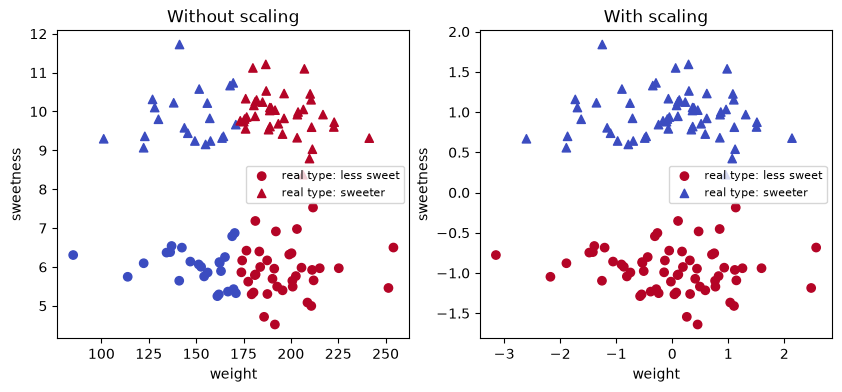

In [3]:
X_scaled = StandardScaler().fit_transform(X)

groups_raw = KMeans(n_clusters=2, random_state=0).fit_predict(X)
groups_scaled = KMeans(n_clusters=2, random_state=0).fit_predict(X_scaled)

# shape = real fruit type, colour = group found by the algorithm
less_sweet, sweeter = true_kind == 0, true_kind == 1

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, data, groups, title in [(axes[0], X, groups_raw, "Without scaling"),
                                (axes[1], X_scaled, groups_scaled, "With scaling")]:
    ax.scatter(data[less_sweet, 0], data[less_sweet, 1], c=groups[less_sweet],
               cmap="coolwarm", vmin=0, vmax=1, marker="o", label="real type: less sweet")
    ax.scatter(data[sweeter, 0], data[sweeter, 1], c=groups[sweeter],
               cmap="coolwarm", vmin=0, vmax=1, marker="^", label="real type: sweeter")
    ax.set(title=title, xlabel="weight", ylabel="sweetness")
    ax.legend(loc="center right", fontsize=8)
plt.show()

In [4]:
# k-means numbers its groups 0/1 at random, so we check both ways round
def percent_correct(groups):
    match = (groups == true_kind).mean()
    return max(match, 1 - match) * 100

print(f"without scaling: {percent_correct(groups_raw):.0f} % correct")
print(f"with scaling:    {percent_correct(groups_scaled):.0f} % correct")

without scaling: 52 % correct
with scaling:    100 % correct


🧪 **Try it:** Print `X.std(axis=0)` and `X_scaled.std(axis=0)`. Why does weight win without scaling?

In [6]:
# --- Solution ---
print("std before scaling [weight, sweetness]:", X.std(axis=0).round(2))
print("std after scaling  [weight, sweetness]:", X_scaled.std(axis=0).round(2))

# What we see:
# - Before scaling: weight has a std of about 30 g, sweetness only about 2.
#   A typical difference in weight is about 15 times bigger than a typical difference in sweetness,
#   so weight decides the distance and k-means splits the fruit into light and heavy.
# - After scaling: both have std 1, so both count equally. Now the big gap in sweetness
#   (the real difference between the fruit types) is what separates the groups.

std before scaling [weight, sweetness]: [29.57  2.07]
std after scaling  [weight, sweetness]: [1. 1.]


## 2. Many dimensions
Put 500 random points in a space with `d` dimensions. How much farther away is the **farthest** point than the **nearest**?

In [10]:
for d in [2, 10, 100, 1000]:
    points = rng.random((500, d))
    query = rng.random(d)
    distances = np.linalg.norm(points - query, axis=1)
    print(f"{d:5d} dimensions: farthest is {distances.max() / distances.min():5.1f} times the nearest")

    2 dimensions: farthest is 139.4 times the nearest
   10 dimensions: farthest is   3.2 times the nearest
  100 dimensions: farthest is   1.4 times the nearest
 1000 dimensions: farthest is   1.1 times the nearest


The numbers change a little each run (the points are random), but the pattern is always the same:
with many dimensions, all points are about equally far away. Then "nearest" means little.

🧪 **Try it:** Draw a histogram of `distances` for `d = 2` and for `d = 1000` (`plt.hist(distances, bins=30)`).
What happens to the shape?

    2D: nearest 0.02, farthest 0.95, mean 0.45, spread (std / mean) 46%
 1000D: nearest 12.21, farthest 13.47, mean 12.86, spread (std / mean) 2%


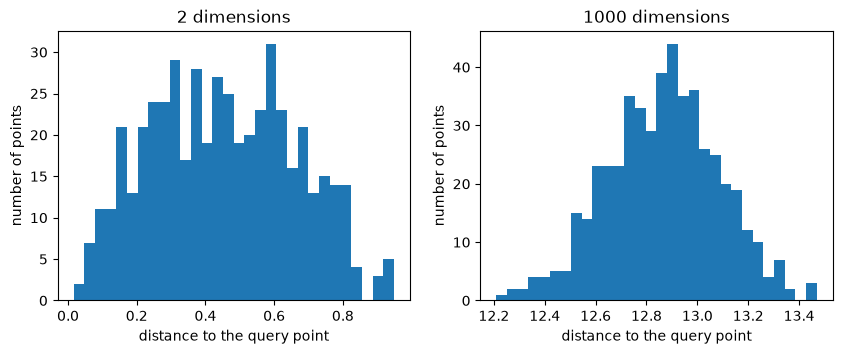

In [17]:
# --- Solution ---
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
for ax, d in zip(axes, [2, 1000]):
    points = rng.random((500, d))
    query = rng.random(d)
    distances = np.linalg.norm(points - query, axis=1)
    ax.hist(distances, bins=30)
    ax.set(title=f"{d} dimensions", xlabel="distance to the query point", ylabel="number of points")
    print(f"{d:5d}D: nearest {distances.min():.2f}, farthest {distances.max():.2f}, "
          f"mean {distances.mean():.2f}, spread (std / mean) {distances.std() / distances.mean():.0%}")
plt.show()

# What we see:
# - 2D: the distances are spread out from almost 0 to about 1.1. Some points are really near, some really far.
# - 1000D: all distances are squeezed into a narrow peak around 12.8 (spread only about 2 % of the mean).
#   Every point is roughly equally far from the query point.
# - The shape goes from wide and flat to a narrow peak. That is why "the nearest neighbour"
#   means little in high dimensions: it is hardly nearer than any other point.

## 3. PCA in practice
The digits: 1797 images of 8×8 pixels = **64 features**. All pixels have the same unit (0–16), so we skip scaling here.

In [18]:
X_digits, y_digits = load_digits(return_X_y=True)
print(X_digits.shape)

(1797, 64)


### How many components to keep?

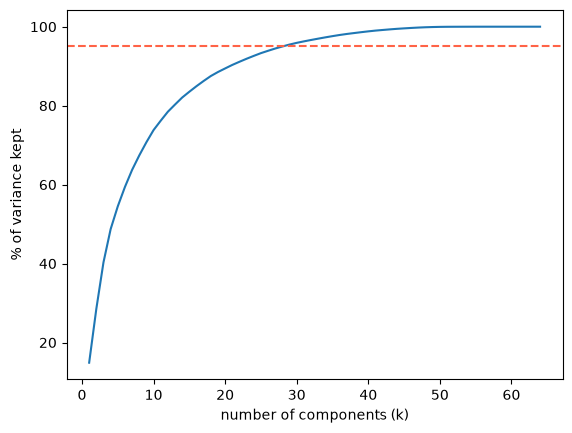

components needed for 95 %: 29


In [19]:
pca = PCA().fit(X_digits)                                   # all 64 components
kept = np.cumsum(pca.explained_variance_ratio_) * 100       # % kept with 1, 2, 3 ... components

plt.plot(range(1, 65), kept)
plt.axhline(95, ls="--", c="tomato")
plt.xlabel("number of components (k)")
plt.ylabel("% of variance kept")
plt.show()

print("components needed for 95 %:", np.argmax(kept >= 95) + 1)

### What do we lose?
Compress one image to `k` numbers, then rebuild it.

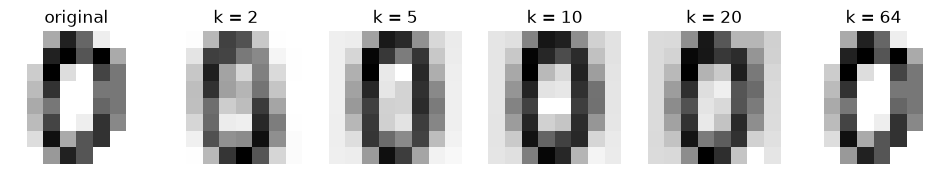

In [20]:
image = X_digits[0]
ks = [2, 5, 10, 20, 64]

fig, axes = plt.subplots(1, len(ks) + 1, figsize=(12, 2.5))
axes[0].imshow(image.reshape(8, 8), cmap="gray_r")
axes[0].set_title("original")
for ax, k in zip(axes[1:], ks):
    pca_k = PCA(n_components=k).fit(X_digits)
    small = pca_k.transform([image])              # 64 numbers -> k numbers
    rebuilt = pca_k.inverse_transform(small)      # k numbers -> 64 numbers
    ax.imshow(rebuilt.reshape(8, 8), cmap="gray_r")
    ax.set_title(f"k = {k}")
for ax in axes:
    ax.axis("off")
plt.show()

With `k = 64` we keep everything, so we get an exact copy back. Fewer components = smaller, but blurrier.

### Fewer features, same accuracy?
We train a nearest-neighbour classifier (next week's topic) on `k` components and test it.

In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X_digits, y_digits, test_size=0.3, random_state=0, stratify=y_digits)

for k in [2, 5, 10, 20, 30, 64]:
    model = make_pipeline(PCA(n_components=k), KNeighborsClassifier())
    model.fit(X_train, y_train)                   # PCA learns from training data only
    print(f"k = {k:2d}: {model.score(X_test, y_test) * 100:.1f} % correct")

k =  2: 60.6 % correct
k =  5: 92.2 % correct
k = 10: 96.9 % correct
k = 20: 97.4 % correct
k = 30: 98.3 % correct
k = 64: 98.0 % correct


### Don't trust every 2D plot
t-SNE takes a few seconds.

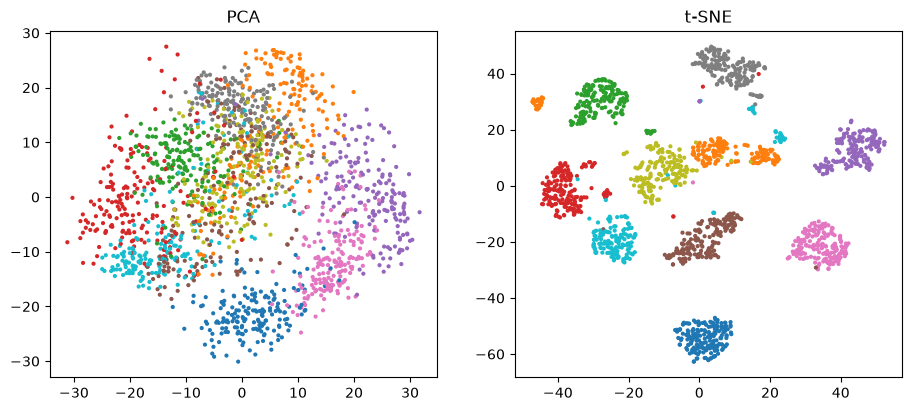

In [22]:
Z_pca = PCA(n_components=2).fit_transform(X_digits)
Z_tsne = TSNE(n_components=2, random_state=0).fit_transform(X_digits)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(Z_pca[:, 0], Z_pca[:, 1], c=y_digits, cmap="tab10", s=4)
axes[0].set_title("PCA")
axes[1].scatter(Z_tsne[:, 0], Z_tsne[:, 1], c=y_digits, cmap="tab10", s=4)
axes[1].set_title("t-SNE")
plt.show()

- **PCA:** distances in the plot are honest, but groups overlap.
- **t-SNE:** clear islands, but island sizes and the gaps between them mean nothing.

🧪 **Try it:** Run t-SNE again with `random_state=1`. Do the islands end up in the same places?

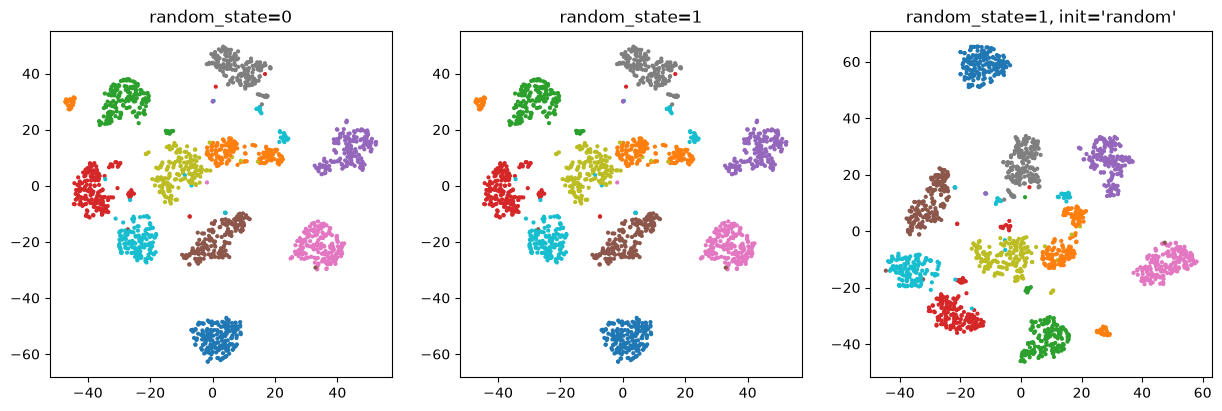

In [23]:
# --- Solution ---
Z_tsne1 = TSNE(n_components=2, random_state=1).fit_transform(X_digits)
# Extra: start from random positions instead of the default PCA start
Z_tsne1_random = TSNE(n_components=2, random_state=1, init="random").fit_transform(X_digits)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, Z, title in zip(axes, [Z_tsne, Z_tsne1, Z_tsne1_random],
                        ["random_state=0", "random_state=1", "random_state=1, init='random'"]):
    ax.scatter(Z[:, 0], Z[:, 1], c=y_digits, cmap="tab10", s=4)
    ax.set_title(title)
plt.show()

# What we see:
# - random_state=0 and random_state=1 give the SAME picture. Newer scikit-learn (1.2+) starts t-SNE
#   from a PCA layout (init="pca"), so the start is fixed and the seed hardly matters.
# - With init="random" the islands are the same groups of digits, but they land in other places
#   (for example, the 0s move from the bottom to the top).
# - Lesson: which points end up together is stable. WHERE the islands are, and the gaps between them, mean nothing.
#   The picture also changes if you change perplexity.

## 4. Teaser for next week: no labels
The same plot, but without the colours. This is **unsupervised learning**.

In [ ]:
plt.scatter(Z_tsne[:, 0], Z_tsne[:, 1], s=4, c="gray")
plt.title("1797 digits, no labels")
plt.show()

🧪 **Discuss:**
1. How many groups do you see?
2. What would an algorithm need to find them? (Hint: everything from today.)
3. How could you tell if the groups are *good*, without the labels?

Next week: **k-means, distance metrics, nearest neighbours and evaluating clusters.**